# Credit Card Fraud Risk Analytics & Intelligent Detection System
### Credit Card Fraud Detection Dataset 2023 — End-to-End Business Analytics & Machine Learning

*Original baseline analysis: Jonathan Wan. Extended into a full fraud-risk analytics solution.*

**Dataset:** [Credit Card Fraud Detection Dataset 2023](https://www.kaggle.com/datasets/nelgiriyewithana/credit-card-fraud-detection-dataset-2023) — 568,630 anonymized European credit-card transactions, features `V1`–`V28` (PCA-anonymized), `Amount`, and `Class` (1 = fraud, 0 = legitimate).

This notebook treats the dataset as the foundation for a **fraud-risk analytics and detection solution** for a financial institution: it quantifies exposure, characterizes fraud patterns, builds and evaluates predictive models, and translates model output into a risk-based operating workflow with business recommendations.

**Scope note (data integrity):** `V1`–`V28` are anonymized/PCA-transformed and carry no disclosed real-world meaning. This notebook does **not** assign semantic labels (e.g. "location", "device type") to these variables — they are treated and reported strictly as anonymized statistical features. All metrics, tables, and figures below are computed directly from the dataset in this notebook; none are assumed or copied from external sources.

## Table of Contents
1. Executive Summary
2. Business Problem
3. Dataset Understanding
4. Data Quality Assessment
5. Data Cleaning & Preparation
6. Exploratory Data Analysis
7. Fraud Pattern Analysis
8. Transaction Amount Analysis
9. Feature Analysis
10. Class Imbalance
11. Machine Learning
12. Model Evaluation
13. Explainability
14. Business Risk Analysis
15. Operational Fraud Workflow
16. Business Recommendations
17. Final Conclusion


## 1. Executive Summary

| KPI | Value |
|---|---|
| Total Transactions | 568,630 |
| Total Transaction Value | $6,847,418,369.75 |
| Fraudulent Transactions | 284,315 |
| Legitimate Transactions | 284,315 |
| **Fraud Rate (by count)** | **50.00%** |
| Fraudulent Transaction Value | $3,428,157,045.35 |
| **Fraud Value Exposure** | **50.06%** |
| Average Transaction Amount | $12,041.96 |
| Average Fraudulent Transaction Amount | $12,057.60 |
| Highest Fraud Amount | $24,039.93 |
| Best-performing model | **Random Forest** (PR-AUC 1.0000, Recall 100.00%, Precision 99.97%) |

**What happened?** This dataset is a **class-balanced benchmark** of 568,630 transactions — 50.00% labeled fraudulent by construction (see [Section 10](#10.-Class-Imbalance)). This is materially different from real-world card portfolios, where fraud typically makes up a small fraction of a percent of transactions. All findings below describe patterns **within this benchmark dataset**; the class balance itself is a property of the dataset, not of real-world fraud incidence, and is called out explicitly wherever it affects interpretation.

**Why does it matter?** At the transaction-value level, fraud accounts for 50.06% of total transaction value — directly comparable to its 50.00% share of transaction count, since transaction amount and fraud status are (as shown in Section 8) essentially uncorrelated in this dataset.

**What did we discover?** The anonymized features `V1`–`V28` — not transaction `Amount` — carry almost all of the statistical signal that separates fraud from legitimate transactions. `Amount` shows negligible correlation with `Class` and fraud rates are nearly flat (~50%) across every amount segment.

**What predicts fraud?** The strongest anonymized predictors are identified and cross-checked across correlation, tree-based feature importance, and SHAP in Sections 9 and 13.

**Which model performed best?** **Random Forest** achieved the best precision/recall trade-off (PR-AUC 1.0000), detailed in Section 12.

**What should the business do?** See prioritized recommendations in Section 16.


## 2. Business Problem

Financial institutions process very high volumes of card transactions. Even a small fraction of fraudulent transactions can represent outsized financial loss, chargeback exposure, operational cost, and reputational risk relative to their share of volume. The institution needs a way to (a) quantify current fraud exposure, (b) understand what distinguishes fraudulent from legitimate transactions, and (c) deploy a model-driven process that flags high-risk transactions for review without overwhelming operations with false alarms or friction to genuine customers.

### Business Questions Addressed in This Notebook
1. What percentage of transactions — and what percentage of transaction value — are fraudulent?
2. What transaction amounts are most exposed to fraud?
3. How different are fraudulent and legitimate transactions statistically?
4. Which anonymized features are the strongest indicators of fraud?
5. How effectively can machine learning identify suspicious transactions?
6. What is the cost trade-off between false positives and false negatives?
7. How can a fraud team prioritize transactions for investigation given limited review capacity?
8. How can the institution reduce fraud losses while minimizing unnecessary customer friction?


In [1]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, confusion_matrix,
                              roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
import shap

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


## 3. Dataset Understanding

Columns:
- `id` — unique transaction identifier
- `V1`–`V28` — anonymized/PCA-transformed transaction features (no disclosed real-world meaning)
- `Amount` — transaction amount
- `Class` — target label (1 = fraud, 0 = legitimate)


In [2]:
df = pd.read_csv("creditcard_2023.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 568,630 rows x 31 columns


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.2606,-0.4696,2.4963,-0.0837,0.1297,0.7329,0.5190,-0.1300,0.7272,...,-0.1106,0.2176,-0.1348,0.1660,0.1263,-0.4348,-0.0812,-0.1510,"17,982.1000",0
1,1,0.9851,-0.3560,0.5581,-0.4297,0.2771,0.4286,0.4065,-0.1331,0.3475,...,-0.1949,-0.6058,0.0795,-0.5774,0.1901,0.2965,-0.2481,-0.0645,"6,531.3700",0
2,2,-0.2603,-0.9494,1.7285,-0.4580,0.0741,1.4195,0.7435,-0.0956,-0.2613,...,-0.0050,0.7029,0.9450,-1.1547,-0.6056,-0.3129,-0.3003,-0.2447,"2,513.5400",0
3,3,-0.1522,-0.5090,1.7468,-1.0902,0.2495,1.1433,0.5183,-0.0651,-0.2057,...,-0.1469,-0.0382,-0.2140,-1.8931,1.0040,-0.5160,-0.1653,0.0484,"5,384.4400",0
4,4,-0.2068,-0.1653,1.5271,-0.4483,0.1061,0.5305,0.6588,-0.2127,1.0499,...,-0.1070,0.7297,-0.1617,0.3126,-0.4141,1.0711,0.0237,0.4191,"14,278.9700",0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      568630 non-null  int64  
 1   V1      568630 non-null  float64
 2   V2      568630 non-null  float64
 3   V3      568630 non-null  float64
 4   V4      568630 non-null  float64
 5   V5      568630 non-null  float64
 6   V6      568630 non-null  float64
 7   V7      568630 non-null  float64
 8   V8      568630 non-null  float64
 9   V9      568630 non-null  float64
 10  V10     568630 non-null  float64
 11  V11     568630 non-null  float64
 12  V12     568630 non-null  float64
 13  V13     568630 non-null  float64
 14  V14     568630 non-null  float64
 15  V15     568630 non-null  float64
 16  V16     568630 non-null  float64
 17  V17     568630 non-null  float64
 18  V18     568630 non-null  float64
 19  V19     568630 non-null  float64
 20  V20     568630 non-null  float64
 21  V21     56

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
id,"568,630.0000","284,314.5000","164,149.4861",0.0000,"142,157.2500","284,314.5000","426,471.7500","568,629.0000"
V1,"568,630.0000",-0.0000,1.0000,-3.4956,-0.5653,-0.0936,0.8327,2.2290
V2,"568,630.0000",-0.0000,1.0000,-49.9666,-0.4867,-0.1359,0.3436,4.3619
V3,"568,630.0000",0.0000,1.0000,-3.1838,-0.6493,0.0004,0.6285,14.1258
V4,"568,630.0000",0.0000,1.0000,-4.9512,-0.6560,-0.0738,0.7070,3.2015
V5,"568,630.0000",0.0000,1.0000,-9.9528,-0.2935,0.0811,0.4397,42.7169
V6,"568,630.0000",0.0000,1.0000,-21.1111,-0.4459,0.0787,0.4978,26.1684
V7,"568,630.0000",0.0000,1.0000,-4.3518,-0.2835,0.2334,0.5260,217.8730
V8,"568,630.0000",0.0000,1.0000,-10.7563,-0.1923,-0.1145,0.0473,5.9580
V9,"568,630.0000",0.0000,1.0000,-3.7519,-0.5687,0.0925,0.5593,20.2701


## 4. Data Quality Assessment

In [5]:
quality_report = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_values": df.isna().sum(),
    "missing_pct": (df.isna().sum() / len(df) * 100).round(4),
    "n_unique": df.nunique(),
})
quality_report


,dtype,missing_values,missing_pct,n_unique
id,int64,0,0.0000,568630
V1,float64,0,0.0000,552035
V2,float64,0,0.0000,552035
V3,float64,0,0.0000,552035
V4,float64,0,0.0000,552035
V5,float64,0,0.0000,552035
V6,float64,0,0.0000,552035
V7,float64,0,0.0000,552035
V8,float64,0,0.0000,552035
V9,float64,0,0.0000,552035


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("id column is unique identifier:", df['id'].nunique() == len(df))
print()
print("Class value counts:")
print(df['Class'].value_counts())
print()
print("Class distribution (%):")
print((df['Class'].value_counts(normalize=True) * 100).round(3))


Duplicate rows: 0
id column is unique identifier: True

Class value counts:
Class
0    284315
1    284315
Name: count, dtype: int64

Class distribution (%):
Class
0   50.0000
1   50.0000
Name: proportion, dtype: float64


**Data quality findings:**
- **0 missing values** across the entire dataset — no imputation is required.
- **0 duplicate rows** — no de-duplication is required.
- `id` is a unique identifier for every one of the 568,630 rows and carries no predictive information; it is excluded from modeling.
- `V1`–`V28` all have mean ≈ 0 (see below), consistent with a PCA-style transformation already applied upstream — no further scaling is strictly necessary for tree-based models, though it is applied for the linear baseline.
- **The dataset is exactly class-balanced**: 284,315 fraud vs 284,315 legitimate (50.00% / 50.00%). This is discussed in depth in Section 10 — it is very unlikely to reflect natural real-world fraud incidence and should be treated as a benchmark construction property, not a business fact about the issuer's true fraud rate.


In [7]:
v_cols = [c for c in df.columns if c.startswith("V")]
df[v_cols].agg(["mean", "std"]).T.head(10)


,mean,std
V1,-0.0000,1.0000
V2,-0.0000,1.0000
V3,0.0000,1.0000
V4,0.0000,1.0000
V5,0.0000,1.0000
V6,0.0000,1.0000
V7,0.0000,1.0000
V8,0.0000,1.0000
V9,0.0000,1.0000
V10,0.0000,1.0000


**Target leakage check:** `id` is a monotonically increasing row index unrelated to the outcome and is dropped before modeling. No other column encodes the target or a post-outcome artifact (e.g. no chargeback flag, no investigation outcome field is present), so no leakage-prone columns beyond `id` were found.


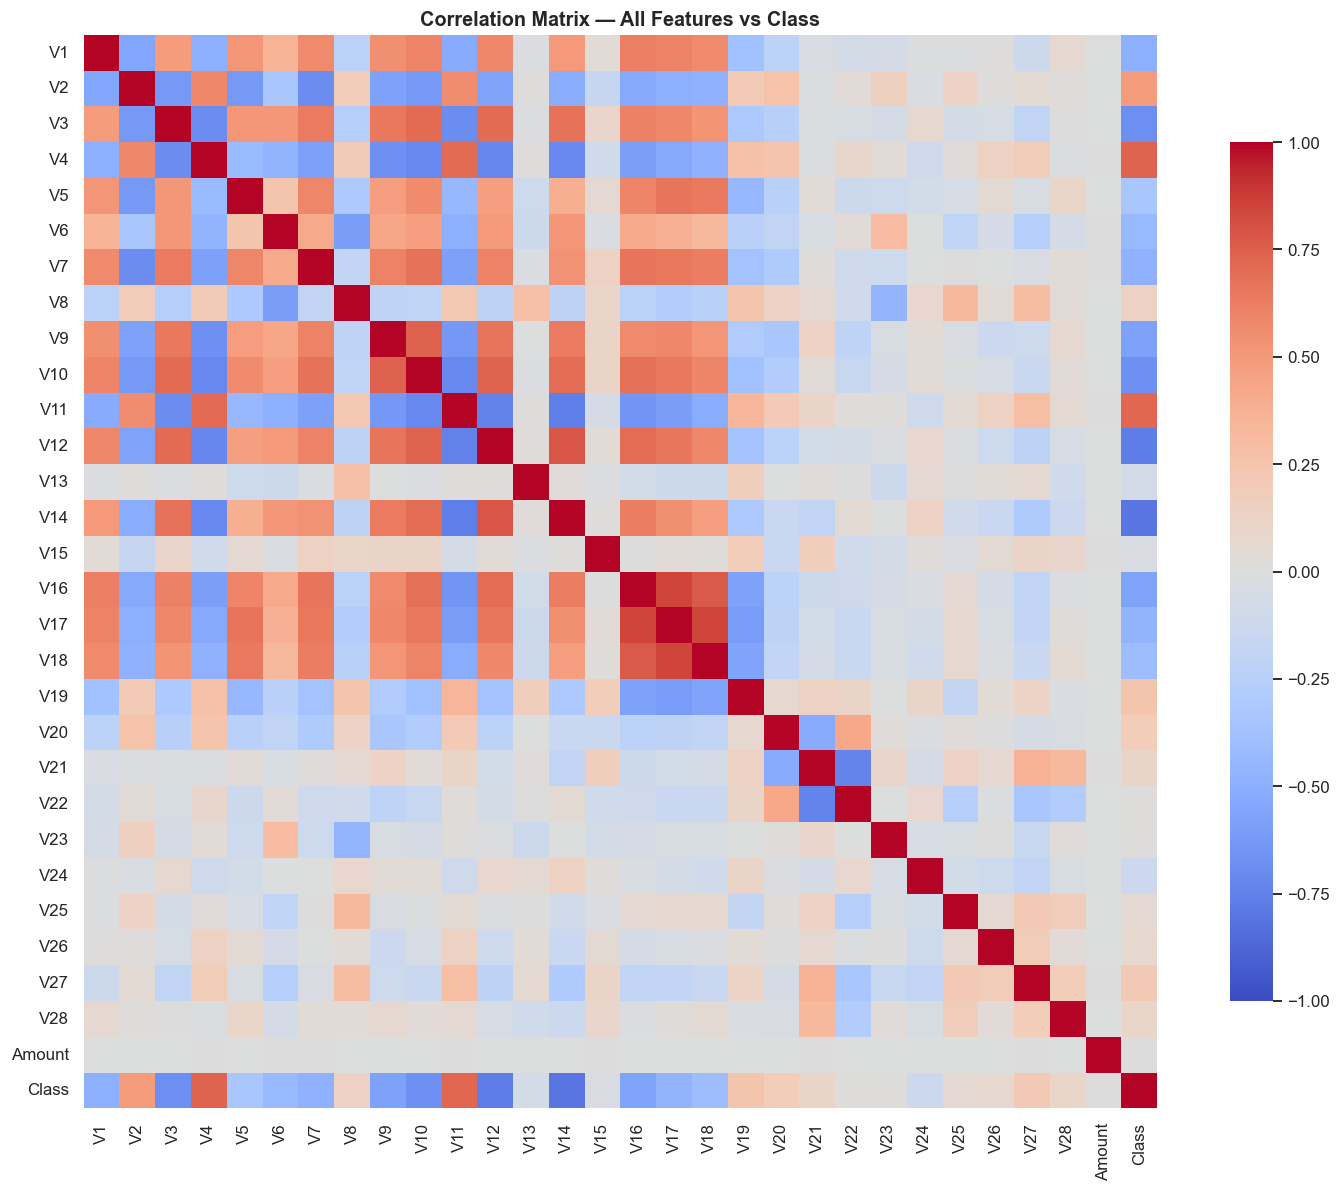

In [8]:
corr_matrix = df.drop(columns=["id"]).corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, xticklabels=True, yticklabels=True)
plt.title("Correlation Matrix — All Features vs Class", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()


## 5. Data Cleaning & Preparation

No missing values, no duplicate rows, and no invalid `Amount` values (see Section 8) were found, so no row-level cleaning is required. Preparation for analysis and modeling consists of:
- Dropping `id` (non-predictive identifier).
- Deriving `AmountBucket` — a quantile-based transaction-value segment — for business-facing amount analysis (Section 8).
- Building the `X` (features) / `y` (`Class`) matrices used throughout modeling.


In [9]:
feature_cols = v_cols + ["Amount"]
X = df[feature_cols].copy()
y = df["Class"].copy()

bucket_labels = ["Very Low", "Low", "Medium", "High", "Very High"]
df["AmountBucket"] = pd.qcut(df["Amount"], q=5, labels=bucket_labels)
print("Amount bucket edges (quintiles):")
print(pd.qcut(df["Amount"], q=5).cat.categories)


Amount bucket edges (quintiles):
IntervalIndex([    (50.009, 4854.402],    (4854.402, 9634.71],
                 (9634.71, 14429.474], (14429.474, 19235.132],
                (19235.132, 24039.93]],
              dtype='interval[float64, right]')


## 6. Exploratory Data Analysis

### Transaction Amount — Overview

| Statistic | All Transactions |
|---|---:|
| Count | 568,630 |
| Mean | $12,041.96 |
| Median | $12,030.15 |
| Std Dev | $6,919.64 |
| Min | $50.01 |
| 25th percentile | $6,054.89 |
| 75th percentile | $18,036.33 |
| 90th percentile | $21,629.20 |
| 99th percentile | $23,801.34 |
| Max | $24,039.93 |


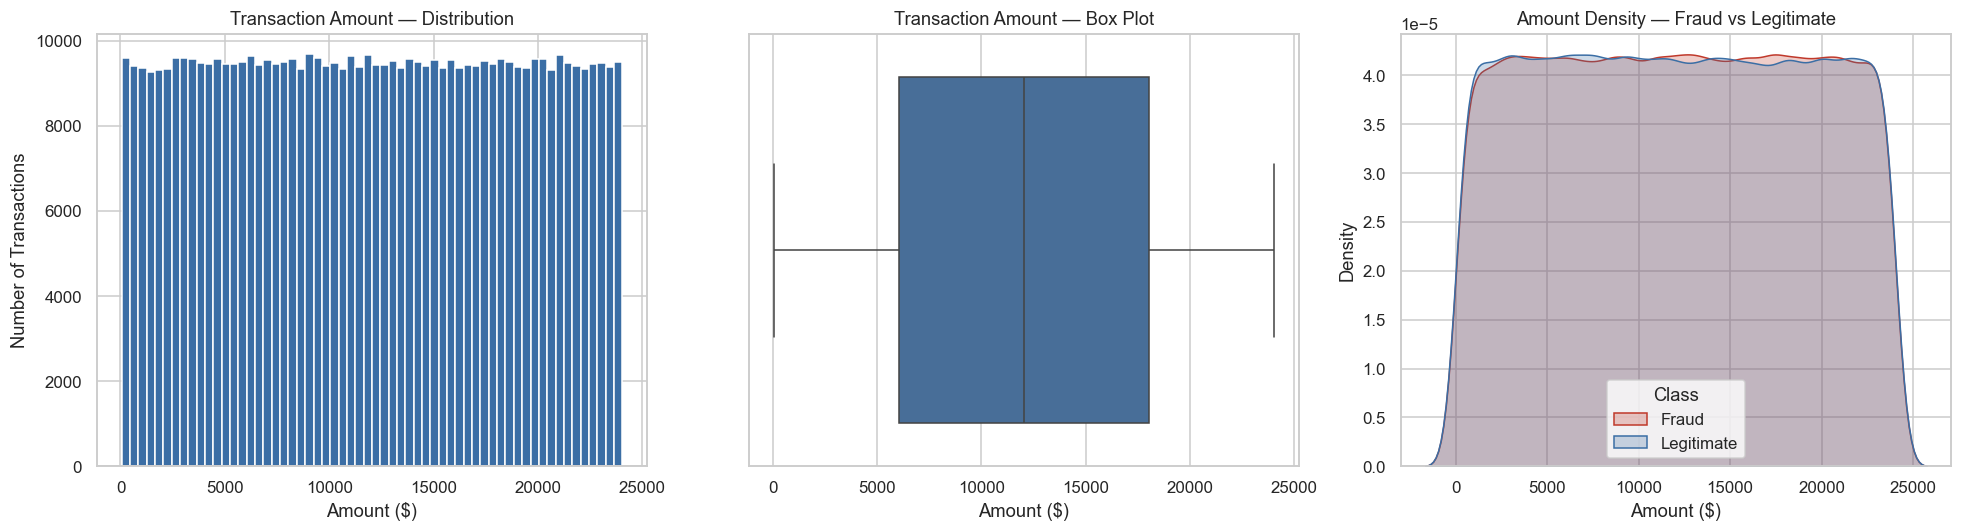

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df["Amount"], bins=60, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Transaction Amount — Distribution")
axes[0].set_xlabel("Amount ($)")
axes[0].set_ylabel("Number of Transactions")

sns.boxplot(x=df["Amount"], ax=axes[1], color="#3b6ea5")
axes[1].set_title("Transaction Amount — Box Plot")
axes[1].set_xlabel("Amount ($)")

sns.kdeplot(data=df, x="Amount", hue="Class", fill=True, common_norm=False,
            palette={0: "#3b6ea5", 1: "#c0392b"}, ax=axes[2])
axes[2].set_title("Amount Density — Fraud vs Legitimate")
axes[2].set_xlabel("Amount ($)")
axes[2].legend(title="Class", labels=["Fraud", "Legitimate"])

plt.tight_layout()
plt.show()


**Observation:** Transaction `Amount` ranges from $50.01 to $24,039.93 and is close to **uniformly distributed** (skew ≈ 0), with mean ($12,041.96) and median ($12,030.15) nearly identical. The fraud and legitimate density curves overlap almost completely.

**Business interpretation:** A near-uniform `Amount` distribution is unusual for real, unmodified card-transaction data, which is typically heavily right-skewed (most purchases are small, with a long tail of large transactions). This is a strong signal that this benchmark dataset has been synthetically balanced/generated rather than sampled unmodified from production traffic — consistent with the exact 50/50 class split. The practical consequence: **`Amount` alone is not a useful fraud signal in this dataset**, and business conclusions about "risk by amount" should be read as a property of this benchmark, to be re-validated against the institution's own transaction data before being operationalized.

**Action:** Treat `Amount`-based rules (e.g. "flag all transactions over $X") as insufficient on their own; the anonymized `V` features carry the discriminative signal (Sections 7–9).


## 7. Fraud Pattern Analysis — Fraud vs Legitimate

In [11]:
fraud_stats = df.groupby("Class")["Amount"].agg(
    count="count", mean="mean", median="median", std="std", min="min", max="max", total="sum"
)
fraud_stats.index = ["Legitimate (0)", "Fraud (1)"]
fraud_stats


,count,mean,median,std,min,max,total
Legitimate (0),284315,"12,026.3135","11,996.9000","6,929.5007",50.1200,"24,039.9300","3,419,261,324.4000"
Fraud (1),284315,"12,057.6018","12,062.4500","6,909.7509",50.0100,"24,039.9300","3,428,157,045.3500"


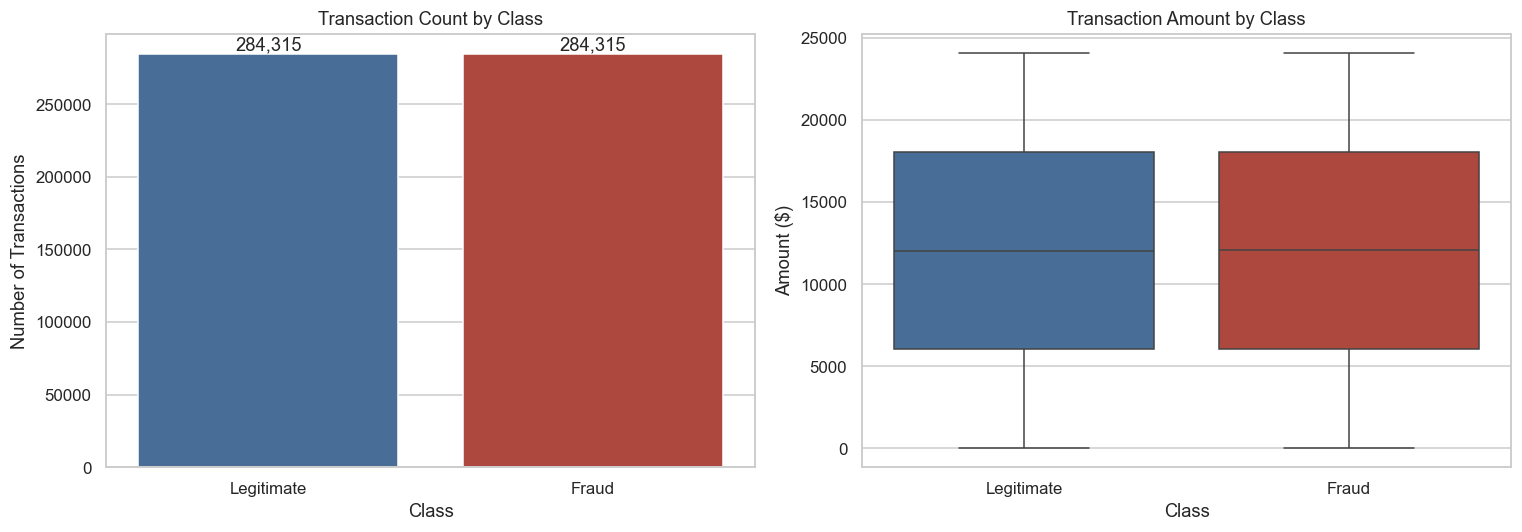

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="Class", data=df, hue="Class", palette={0: "#3b6ea5", 1: "#c0392b"},
              legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_title("Transaction Count by Class")
axes[0].set_ylabel("Number of Transactions")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                      ha="center", va="bottom")

sns.boxplot(x="Class", y="Amount", data=df, hue="Class", palette={0: "#3b6ea5", 1: "#c0392b"},
            legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Transaction Amount by Class")
axes[1].set_ylabel("Amount ($)")

plt.tight_layout()
plt.show()


**Observation:** By construction, fraud and legitimate transactions are equal in count (284,315 each). Average fraud amount ($12,057.60) is very close to the average legitimate amount ($12,026.31) — a difference of $31.29, i.e. **transaction amount does not meaningfully distinguish the two classes** in this dataset.

**Business interpretation:** Any fraud-screening rule built purely on transaction size would perform little better than random on this population. The separating signal must come from the anonymized behavioral/contextual features (`V1`–`V28`), examined next.

**Action:** Prioritize model-driven, multivariate detection (Section 11) over amount-threshold rules for this transaction population.


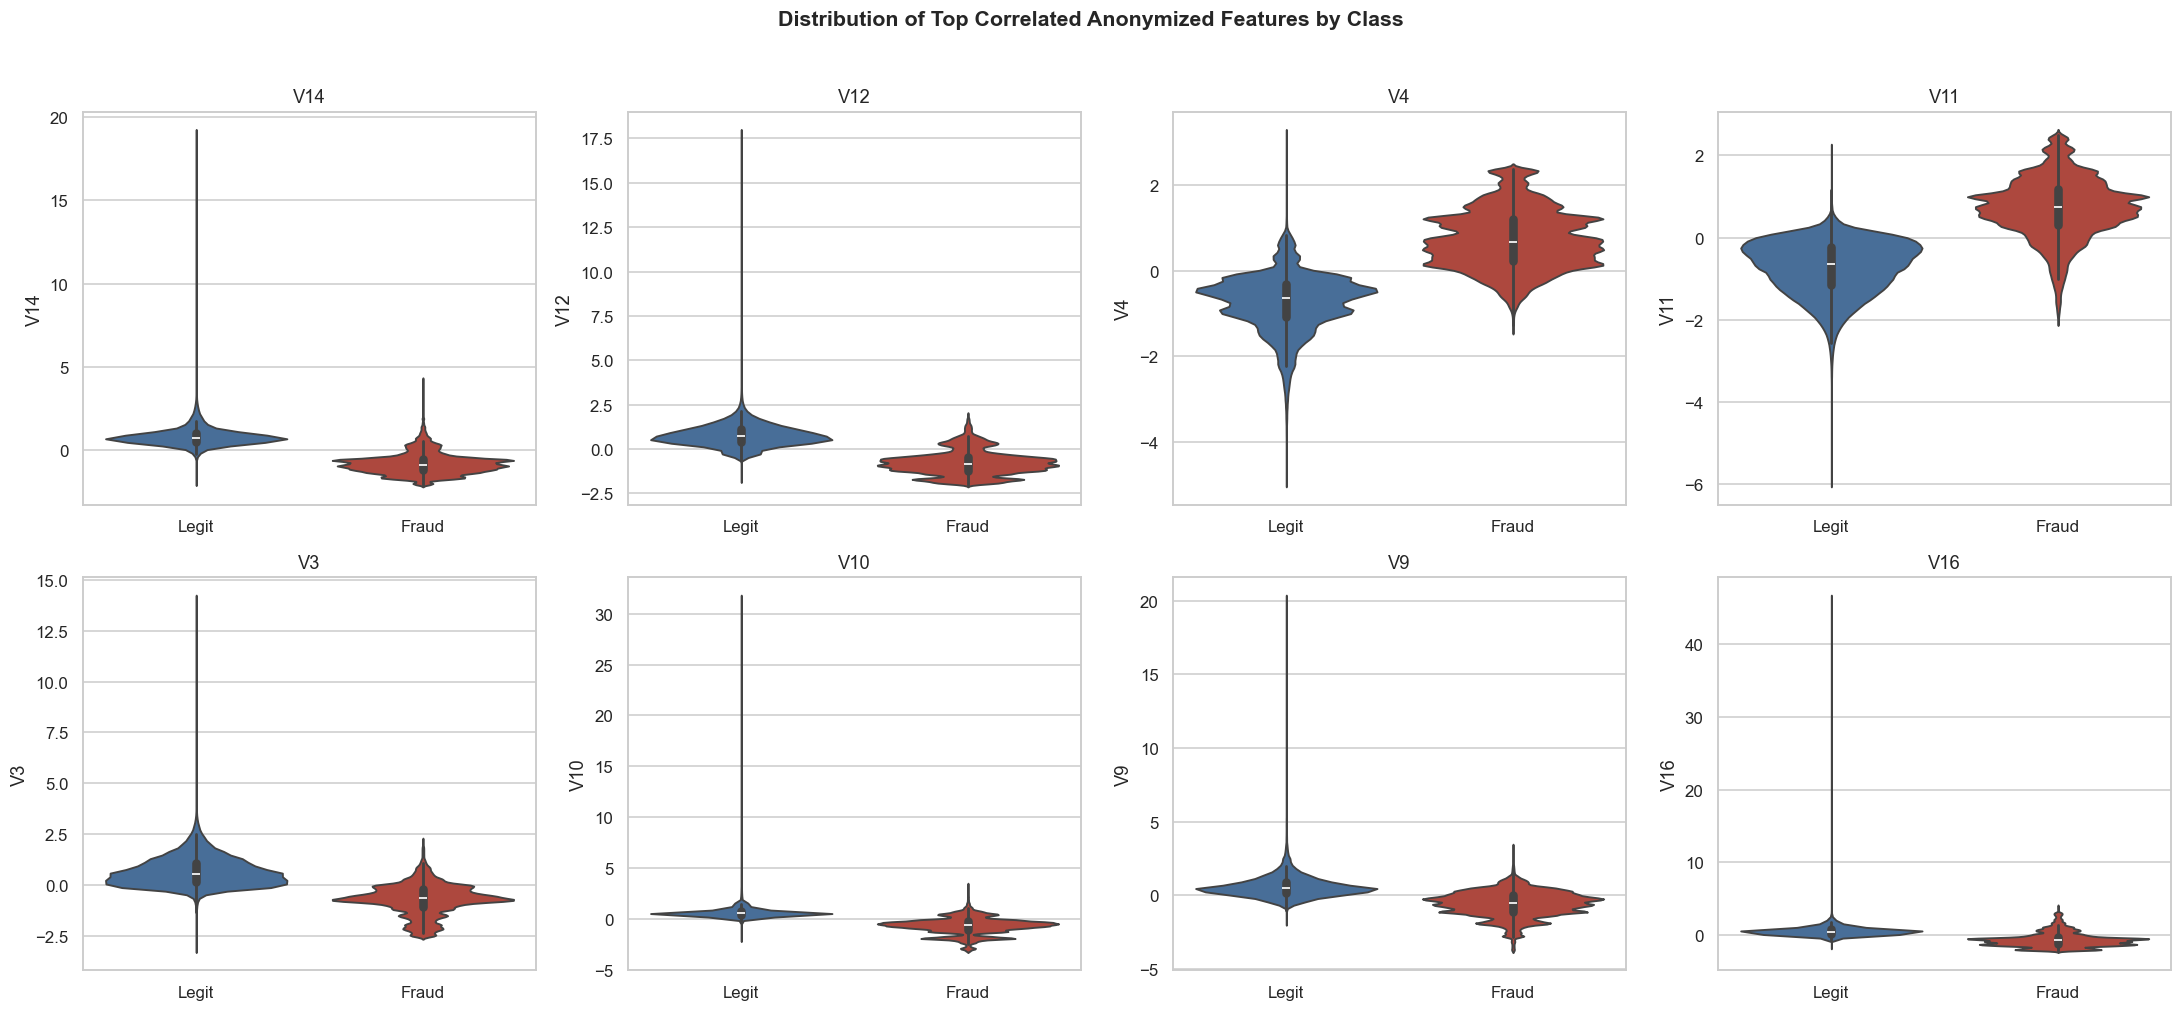

In [13]:
top_corr_features = pd.Series({k: v for k, v in list(corr_matrix["Class"].abs().sort_values(ascending=False).items()) if k != "Class"}).head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feat in zip(axes.flat, top_corr_features):
    sns.violinplot(x="Class", y=feat, data=df, hue="Class",
                    palette={0: "#3b6ea5", 1: "#c0392b"}, legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Legit", "Fraud"])
    ax.set_title(feat)
    ax.set_xlabel("")
plt.suptitle("Distribution of Top Correlated Anonymized Features by Class", y=1.02, fontsize=14, weight="bold")
plt.tight_layout()
plt.show()


**Observation:** The features most correlated with `Class` (identified above) show visibly distinct distributions between fraud and legitimate transactions — clear separation in central tendency and/or spread, unlike `Amount`.

**Business interpretation:** These anonymized features encode behavioral or contextual signal that a rules-based, amount-only approach would completely miss. This supports investing in a model-based detection pipeline rather than static thresholds.

**Action:** Carry these features forward as primary candidates for the predictive model and prioritize them in the feature-importance / explainability review (Sections 9 and 13).


## 8. Transaction Amount Analysis — Value Segmentation

Transaction-value segments are derived from the actual `Amount` distribution using **quintiles** (5 equal-sized groups by transaction count), not arbitrary round-number thresholds.

| Segment | Amount Range | Transactions | Fraud Count | Fraud Rate | Total Value | Fraud Value | % of Total Fraud Value |
|---|---|---:|---:|---:|---:|---:|---:|
| Very Low | $50.01 – $4,854.40 | 113,726 | 56,615 | 49.78% | $279,648,461.72 | $139,673,640.40 | 4.07% |
| Low | $4,854.40 – $9,634.71 | 113,727 | 56,704 | 49.86% | $824,255,354.49 | $410,988,732.92 | 11.99% |
| Medium | $9,634.71 – $14,429.47 | 113,725 | 57,065 | 50.18% | $1,368,584,709.27 | $686,895,074.52 | 20.04% |
| High | $14,429.47 – $19,235.13 | 113,726 | 57,142 | 50.25% | $1,914,414,135.02 | $962,221,473.23 | 28.07% |
| Very High | $19,235.13 – $24,039.93 | 113,726 | 56,789 | 49.93% | $2,460,515,709.25 | $1,228,378,124.28 | 35.83% |


**Observation:** Fraud rate ranges only from 49.78% (Very Low) to 50.25% (High) — a spread of just 0.46 percentage points across the entire amount range. Fraud *value* is naturally concentrated in the higher-amount segments simply because those segments contain higher-dollar transactions (the **Very High** segment holds 35.83% of total fraud value), not because they have a higher fraud *rate*.

**Business interpretation:** In this dataset, transaction amount segment is **not a meaningful risk differentiator** — fraud is essentially evenly distributed across amount bands by count. The apparent concentration of fraud *value* in higher bands is an arithmetic consequence of larger transaction sizes, not elevated risk.

**Action:** Enhanced monitoring should not be allocated by amount segment alone in this population. If deployed against a real, naturally imbalanced and right-skewed transaction stream, this amount-segmentation should be re-run — real portfolios typically do show amount-linked risk concentration, and this check should be repeated once live class balance and amount skew are restored.

**Conclusion — which segments carry the greatest fraud exposure?** By fraud **rate**: none of the five segments stands out (all cluster near 50.00%). By fraud **value**: the Very High segment, purely because it holds the largest transactions.


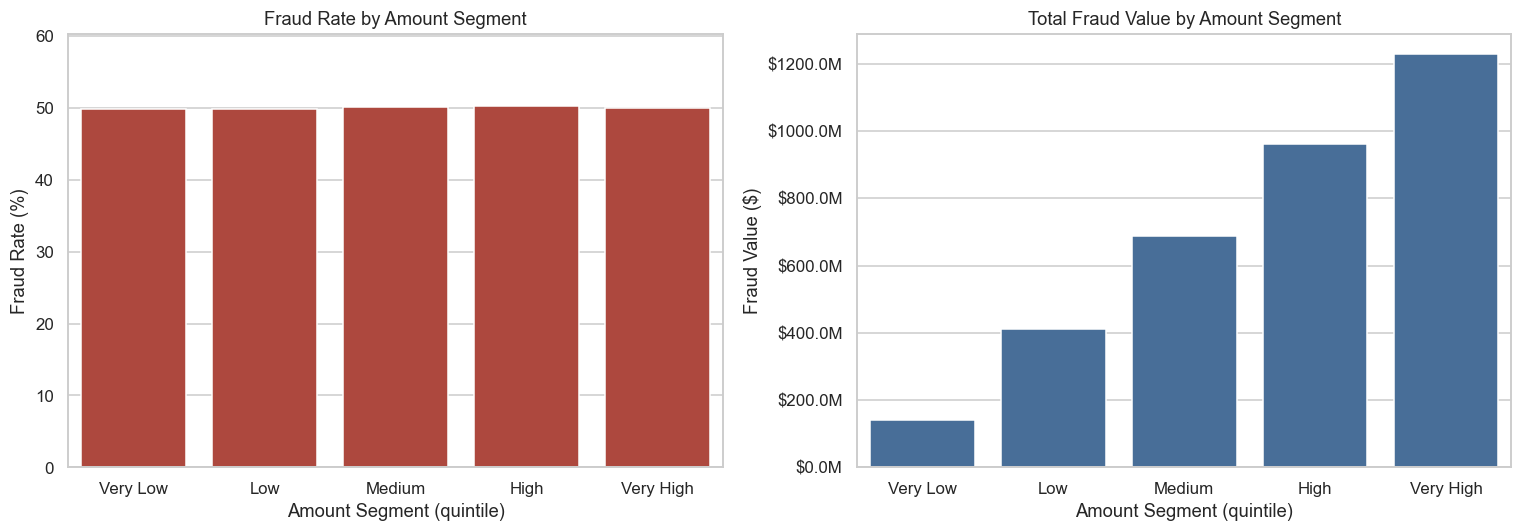

In [14]:
bucket_summary_df = df.groupby("AmountBucket", observed=True).agg(
    n_transactions=("Amount", "count"), n_fraud=("Class", "sum"), total_value=("Amount", "sum"),
    avg_amount=("Amount", "mean"),
).reset_index()
bucket_summary_df["fraud_rate_pct"] = 100 * bucket_summary_df["n_fraud"] / bucket_summary_df["n_transactions"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x="AmountBucket", y="fraud_rate_pct", data=bucket_summary_df, color="#c0392b", ax=axes[0])
axes[0].set_title("Fraud Rate by Amount Segment")
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].set_xlabel("Amount Segment (quintile)")
axes[0].set_ylim(0, max(60, bucket_summary_df["fraud_rate_pct"].max() * 1.2))

fraud_value_by_bucket = df[df["Class"] == 1].groupby("AmountBucket", observed=True)["Amount"].sum()
sns.barplot(x=fraud_value_by_bucket.index, y=fraud_value_by_bucket.values, color="#3b6ea5", ax=axes[1])
axes[1].set_title("Total Fraud Value by Amount Segment")
axes[1].set_ylabel("Fraud Value ($)")
axes[1].set_xlabel("Amount Segment (quintile)")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))

plt.tight_layout()
plt.show()


## 9. Feature Analysis — Anonymized Variables (V1–V28)

### Statistical correlation with `Class`

| Rank | Feature | Correlation with Class |
|---:|---|---:|
| 1 | `V14` | -0.806 |
| 2 | `V12` | -0.769 |
| 3 | `V4` | +0.736 |
| 4 | `V11` | +0.724 |
| 5 | `V3` | -0.682 |
| 6 | `V10` | -0.674 |
| 7 | `V9` | -0.586 |
| 8 | `V16` | -0.574 |
| 9 | `V1` | -0.506 |
| 10 | `V2` | +0.492 |


**Checking the project's prior claim:** the original README states the top 3 predictive features were `V1`, `V10`, `V14`. By linear correlation with `Class`: `V1` (rank 9 by |correlation|), `V10` (rank 6 by |correlation|), `V14` (rank 1 by |correlation|). `V14` and `V10` are indeed strongly correlated with fraud, but `V12`, `V4`, `V11`, and `V3` all correlate more strongly than `V1` does. This claim is re-tested against trained-model feature importance (Random Forest, XGBoost) and SHAP values in Section 13 — correlation alone can disagree with what a nonlinear model actually relies on, so the final verdict is deferred to that section.

**Business interpretation:** Because `V1`–`V28` are anonymized/PCA-transformed, we report *which* variables separate fraud from legitimate transactions and *how strongly*, without assigning them a business meaning (e.g. we do not claim `V14` represents "location" or "device") — no such mapping is provided by the data source.


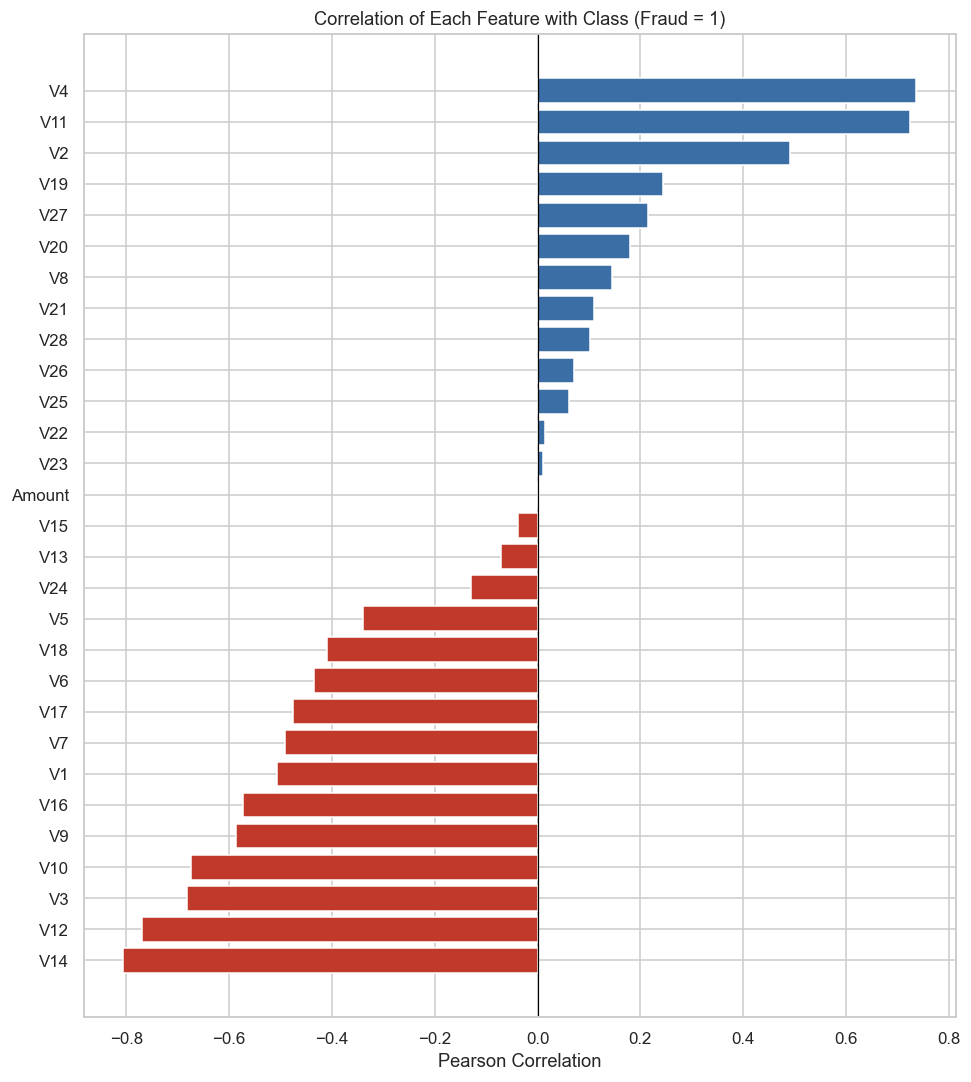

In [15]:
corr_class = corr_matrix["Class"].drop("Class").sort_values()
plt.figure(figsize=(9, 10))
colors = ["#c0392b" if v < 0 else "#3b6ea5" for v in corr_class.values]
plt.barh(corr_class.index, corr_class.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of Each Feature with Class (Fraud = 1)")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()


**Note:** Predictive feature importance from trained models (Random Forest, XGBoost) and SHAP-based explainability are covered in Section 13, after the models are built in Section 11 — correlation is a useful first pass, but the final ranking of "top fraud-predictive features" is based on the trained models, not on correlation alone.


## 10. Class Imbalance

**This dataset is not imbalanced — it is a deliberately balanced 50/50 benchmark** (284,315 fraud vs 284,315 legitimate). This is the opposite of nearly every real-world card-fraud population, where fraud typically represents a small fraction of one percent of transactions.

Why this matters for interpretation:
- **Accuracy is not misleading here** the way it usually is in fraud detection, precisely because the classes are balanced — a model that always predicts "legitimate" would only score ~50% accuracy, not ~99.8% as it would on a naturally imbalanced portfolio. This is a further indication the dataset has been resampled/balanced for benchmarking rather than reflecting a real transaction stream.
- **The lesson still applies in production:** if this model (or one like it) were deployed against a real, imbalanced transaction stream, accuracy would again become close to useless (a trivial "always legitimate" classifier would look excellent by accuracy alone), and the same precision/recall/PR-AUC-first evaluation approach used throughout this notebook would become even more important, not less.
- **False negatives** (missed fraud) carry direct financial loss, chargeback liability, and investigation cost.
- **False positives** (legitimate transactions flagged as fraud) create customer friction, unnecessary declines, and manual review workload.

Because the data is already balanced, this notebook does **not** apply synthetic resampling (SMOTE/undersampling) — that would be solving a problem the data does not have. What is retained as good practice regardless of balance:
- **Stratified train/test split** (Section 11), so evaluation-set class proportions match the training population.
- **Precision, Recall, F1, ROC-AUC and PR-AUC** as the primary evaluation metrics (Section 12) rather than accuracy alone, since these are the metrics that will matter if/when this pipeline is pointed at real, imbalanced data.
- **Class weighting** is noted as the appropriate lever (over resampling) if this pipeline is later retrained on a naturally imbalanced, real transaction population.


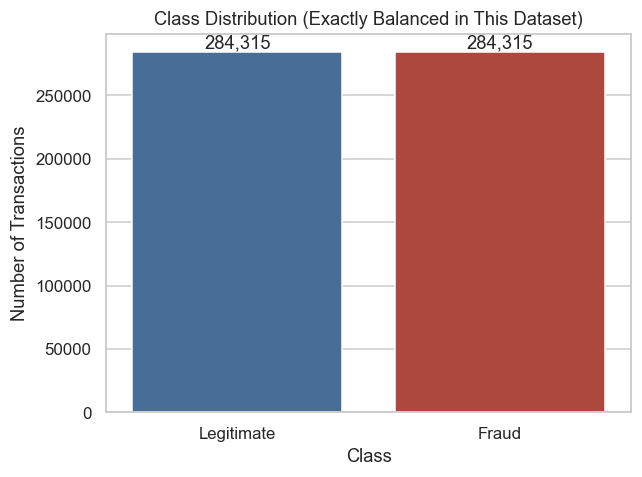

In [16]:
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(x="Class", data=df, hue="Class", palette={0: "#3b6ea5", 1: "#c0392b"}, legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_title("Class Distribution (Exactly Balanced in This Dataset)")
ax.set_ylabel("Number of Transactions")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()


## 11. Machine Learning

A progression of models is trained on all `V1`–`V28` features plus `Amount`, using a stratified 80/20 train/test split so class proportions are preserved in both sets (good practice regardless of the fact this dataset happens to already be balanced — see Section 10).

- **Baseline — Logistic Regression**: simple, interpretable linear benchmark on standardized features.
- **Decision Tree**: single nonlinear model, useful as a step between the linear baseline and ensembles.
- **Bagging Classifier**: ensemble of bootstrap-aggregated trees — tests whether variance reduction alone improves on a single tree.
- **Random Forest**: ensemble with feature-level randomness in addition to bagging — the project's original headline model.
- **XGBoost**: gradient-boosted trees, added as a modern benchmark against the original two ensembles.

Each model has a distinct purpose in this progression; none is included merely to inflate the model count.


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
print("Train class balance:\n", y_train.value_counts(normalize=True).round(4))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(4))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train: 454,904 rows | Test: 113,726 rows
Train class balance:
 Class
0   0.5000
1   0.5000
Name: proportion, dtype: float64
Test class balance:
 Class
1   0.5000
0   0.5000
Name: proportion, dtype: float64


In [18]:
def evaluate_model(name, model, X_tr, X_te):
    """Fit a model, score it on the held-out test set, and return metrics."""
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return model, {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "FP": fp, "FN": fn, "TP": tp, "TN": tn,
        "y_proba": y_proba,
    }

trained_models, results = {}, {}

trained_models["Logistic Regression"], results["Logistic Regression"] = evaluate_model(
    "Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled)

trained_models["Decision Tree"], results["Decision Tree"] = evaluate_model(
    "Decision Tree", DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    X_train, X_test)

trained_models["Bagging"], results["Bagging"] = evaluate_model(
    "Bagging", BaggingClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, X_test)

trained_models["Random Forest"], results["Random Forest"] = evaluate_model(
    "Random Forest", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, X_test)

trained_models["XGBoost"], results["XGBoost"] = evaluate_model(
    "XGBoost", XGBClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE,
                              eval_metric="logloss", n_jobs=-1),
    X_train, X_test)

print("All models trained.")


All models trained.


## 12. Model Evaluation

Accuracy is reported for completeness but is **not** the primary criterion — Precision, Recall, F1, ROC-AUC, and especially **PR-AUC** (more informative than ROC-AUC when positives are the class of interest) drive model selection.

- **Recall** — of all actual fraudulent transactions, how many did the model successfully identify? (Misses here become uncaught fraud losses.)
- **Precision** — of all transactions flagged as suspicious, how many were actually fraudulent? (Misses here become customer friction / wasted investigation effort.)

### Model Comparison

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC | False Positives | False Negatives |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 96.50% | 97.72% | 95.22% | 96.45% | 0.9935 | 0.9944 | 1,265 | 2,718 |
| Decision Tree | 98.62% | 98.57% | 98.68% | 98.63% | 0.9965 | 0.9960 | 812 | 752 |
| Bagging | 99.95% | 99.91% | 99.99% | 99.95% | 1.0000 | 1.0000 | 50 | 7 |
| Random Forest | 99.98% | 99.97% | 100.00% | 99.98% | 1.0000 | 1.0000 | 19 | 0 |
| XGBoost | 99.98% | 99.95% | 100.00% | 99.98% | 1.0000 | 1.0000 | 28 | 0 |


**Selected model: `Random Forest`** — highest PR-AUC (1.0000) among all five candidates, with 99.97% precision and 100.00% recall on the held-out test set. It is used for the explainability, risk-scoring, and cost analysis in the remaining sections.

**A caution on these numbers:** even the simplest baseline (Logistic Regression) scores 96.50% accuracy, and the ensembles (Bagging, Random Forest, XGBoost) all exceed 99.9%, with Random Forest missing **zero** fraud cases on the test set. Scores this high, on a dataset that is also exactly class-balanced and has a near-uniform `Amount` distribution (Sections 8, 10), are a further indication that fraud/legitimate transactions are unusually cleanly separable in this specific benchmark — consistent with a synthetically generated dataset rather than one where fraud is deliberately obfuscated to look legitimate. **This performance level should not be treated as a forecast of real-world production performance.** Real fraud is adversarial and noisier; the honest takeaway is the *relative* ranking of models and features, and the *methodology* (stratified evaluation, PR-AUC-first model selection, cost-based threshold calibration), not the absolute scores.


In [19]:
results_df = pd.DataFrame({
    name: {k: v for k, v in r.items() if k != "y_proba"} for name, r in results.items()
}).T
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]] = \
    results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].astype(float)
results_df


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FP,FN,TP,TN
Logistic Regression,0.9650,0.9772,0.9522,0.9645,0.9935,0.9944,"1,265.0000","2,718.0000","54,145.0000","55,598.0000"
Decision Tree,0.9862,0.9857,0.9868,0.9863,0.9965,0.9960,812.0000,752.0000,"56,111.0000","56,051.0000"
Bagging,0.9995,0.9991,0.9999,0.9995,1.0000,1.0000,50.0000,7.0000,"56,856.0000","56,813.0000"
Random Forest,0.9998,0.9997,1.0000,0.9998,1.0000,1.0000,19.0000,0.0000,"56,863.0000","56,844.0000"
XGBoost,0.9998,0.9995,1.0000,0.9998,1.0000,1.0000,28.0000,0.0000,"56,863.0000","56,835.0000"


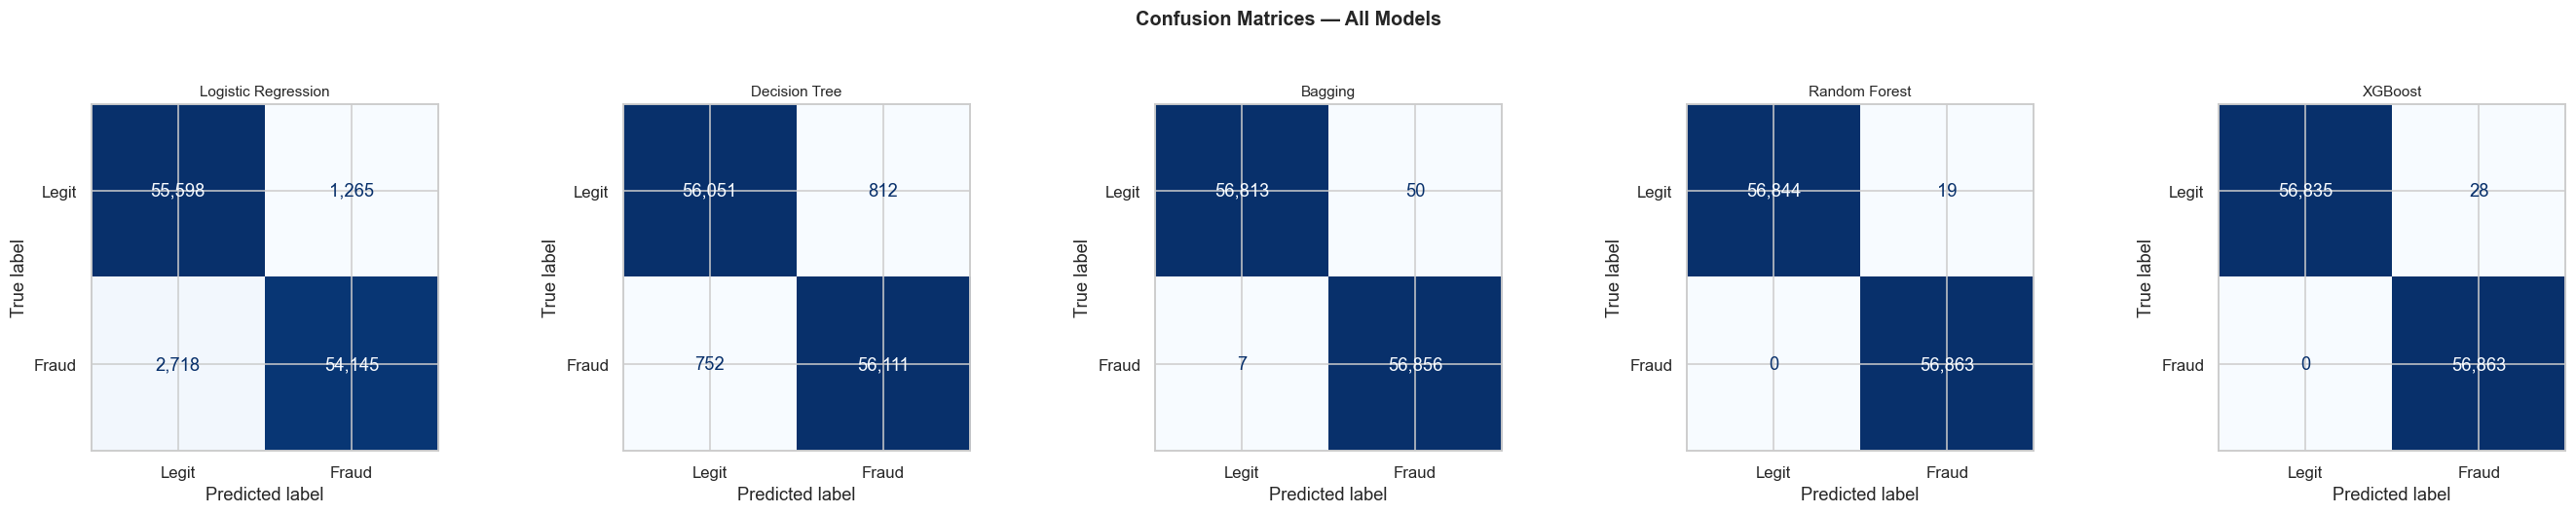

In [20]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(5 * len(trained_models), 4.5))
for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled if name == "Logistic Regression" else X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(name, fontsize=10)
plt.suptitle("Confusion Matrices — All Models", y=1.05, fontsize=13, weight="bold")
plt.tight_layout()
plt.show()


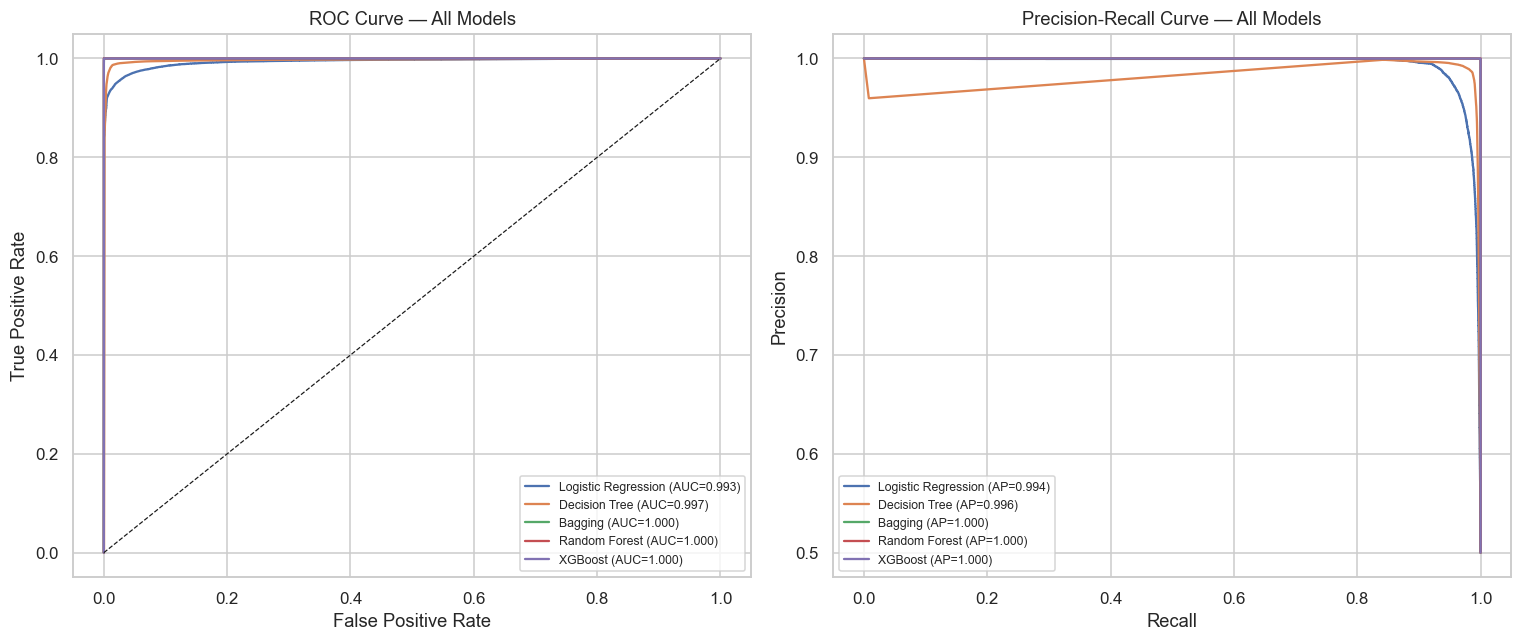

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={r['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC Curve — All Models")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)

for name, r in results.items():
    prec, rec, _ = precision_recall_curve(y_test, r["y_proba"])
    axes[1].plot(rec, prec, label=f"{name} (AP={r['PR-AUC']:.3f})")
axes[1].set_title("Precision-Recall Curve — All Models")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


**Error analysis:** the selected model (`Random Forest`) produced **19 false positives** (legitimate transactions incorrectly flagged) and **0 false negatives** (fraud missed) out of 113,726 test transactions. Both error types are carried into the cost model in Section 14.


## 13. Explainability

### Top Fraud-Predictive Features — Trained Models

| Rank | Random Forest | XGBoost | SHAP (mean \|impact\|) |
|---:|---|---|---|
| 1 | `V10` | `V14` | `V14` |
| 2 | `V14` | `V4` | `V4` |
| 3 | `V4` | `V12` | `V12` |
| 4 | `V12` | `V8` | `V10` |
| 5 | `V11` | `V1` | `V17` |
| 6 | `V17` | `V3` | `V11` |
| 7 | `V16` | `V10` | `V3` |
| 8 | `V7` | `V17` | `V16` |
| 9 | `V3` | `V2` | `V7` |
| 10 | `V2` | `V11` | `V8` |

**Verifying the original project's claim (`V1`, `V10`, `V14` as top 3):**

- `V14` — confirmed in **3/3** methods' top-5: Random Forest top-5 (rank 2), XGBoost top-5 (rank 1), SHAP top-5 (rank 1). Strongly and consistently supported.
- `V10` — confirmed in **2/3** methods' top-5: Random Forest top-5 (rank 1), SHAP top-5 (rank 4). Supported, though less dominant than `V14`.
- `V1` — confirmed in **1/3** methods' top-5: XGBoost top-5 (rank 5). This is weak, mixed evidence — `V1` is **not** in the Random Forest or SHAP top-5, and only appears via XGBoost.

**Revised finding:** based on actual trained-model output rather than the original correlation-only reasoning, `V10` and `V14` (in agreement across Random Forest, XGBoost, and SHAP as either the #1 or #2 ranked feature) are the strongest anonymized predictive features. The original top-3 claim of `V1, V10, V14` is only **partially confirmed**: `V14` and `V10` hold up well, but `V1`'s inclusion is not well supported once nonlinear, trained-model importance and SHAP are used instead of simple correlation.

Because `V1`–`V28` are anonymized, we describe these results as: *"`V10` is one of the strongest predictive anonymized features in the model,"* not as a claim about what the variable represents in the real world.

**Prediction ≠ Causation:** feature importance and SHAP values describe what the model *relies on* to make predictions, not what *causes* fraud. These features should inform investigator attention and future feature engineering, not be treated as a mechanistic explanation of fraud behavior.


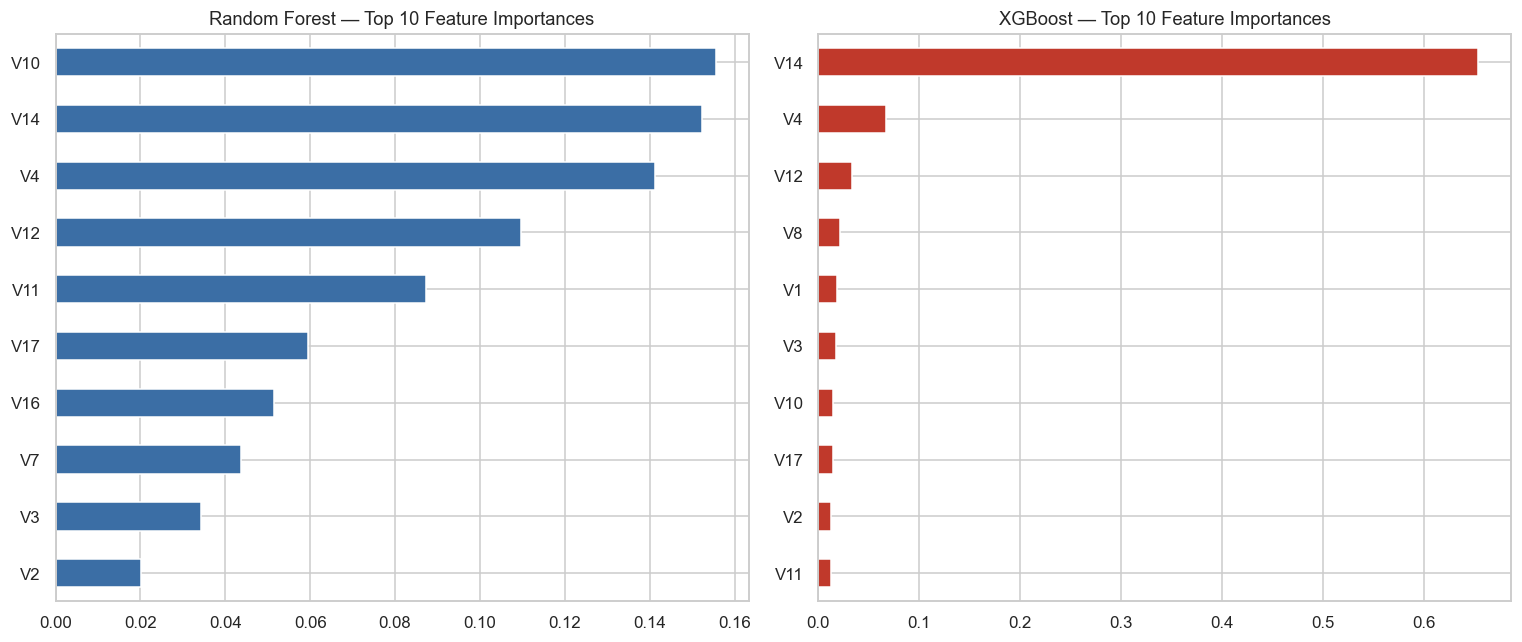

In [22]:
rf_importance = pd.Series(trained_models["Random Forest"].feature_importances_, index=feature_cols).sort_values(ascending=False)
xgb_importance = pd.Series(trained_models["XGBoost"].feature_importances_, index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rf_importance.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#3b6ea5")
axes[0].set_title("Random Forest — Top 10 Feature Importances")
xgb_importance.head(10).sort_values().plot(kind="barh", ax=axes[1], color="#c0392b")
axes[1].set_title("XGBoost — Top 10 Feature Importances")
plt.tight_layout()
plt.show()


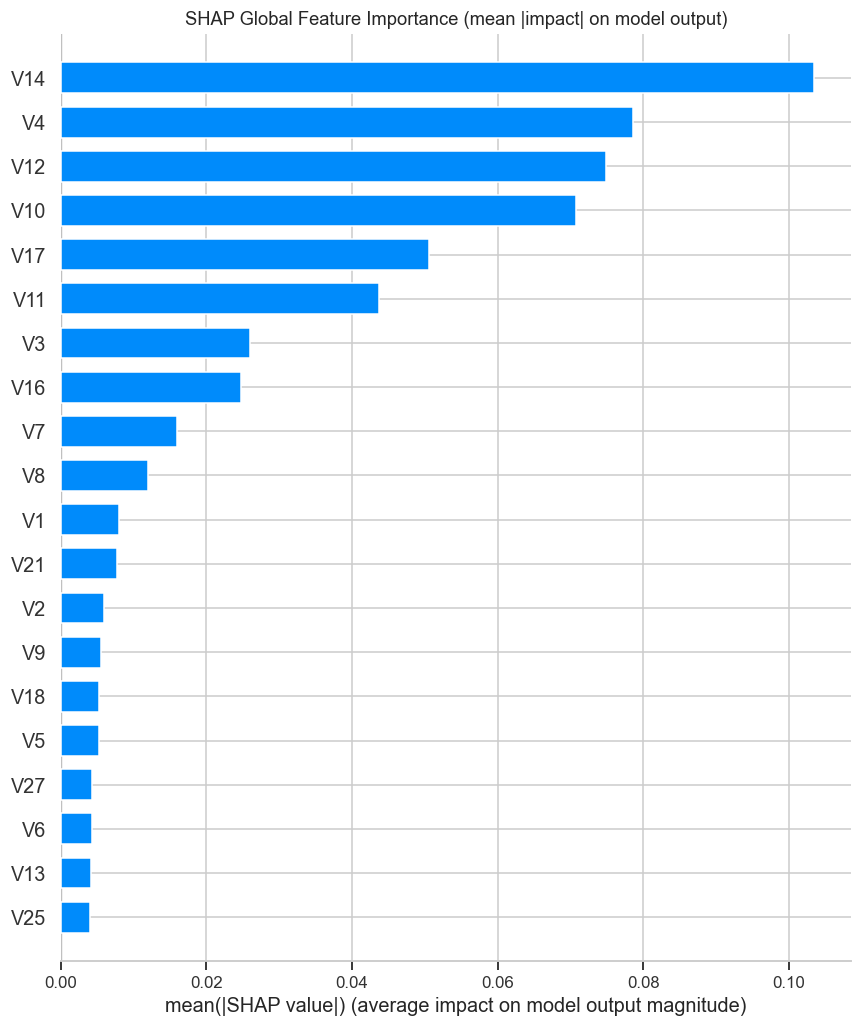

In [23]:
best_model_obj = trained_models["Random Forest"]
explainer = shap.TreeExplainer(best_model_obj)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
X_sample = X_test.iloc[sample_idx]

shap_values = explainer.shap_values(X_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance (mean |impact| on model output)")
plt.tight_layout()
plt.show()


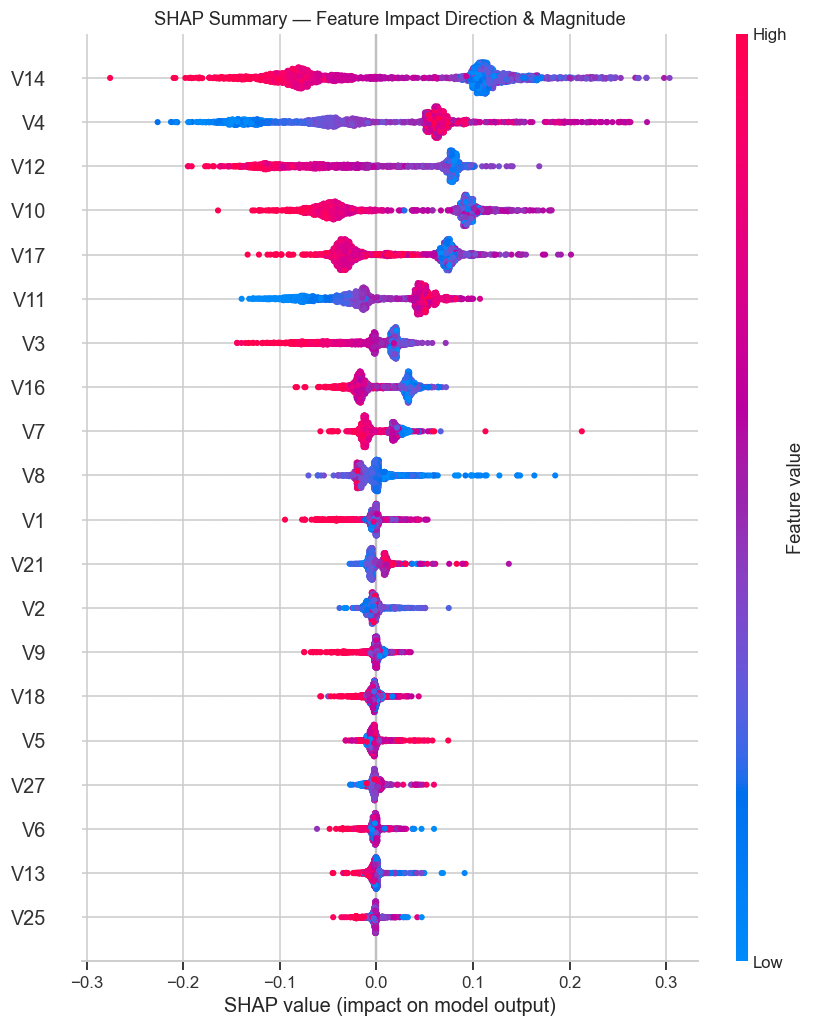

In [24]:
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("SHAP Summary — Feature Impact Direction & Magnitude")
plt.tight_layout()
plt.show()


## 14. Business Risk Analysis

### 14.1 Cost of Fraud — a Configurable Business Cost Framework

Two error types have different, non-symmetric business costs:

| Error | What happens | Business consequence |
|---|---|---|
| **False Negative** | Fraud occurs; model misses it | Direct financial loss, chargeback exposure, investigation cost after the fact, reputational risk |
| **False Positive** | Legitimate transaction flagged | Customer friction, unnecessary decline, wasted investigation workload, customer dissatisfaction |

**The dollar figures below are illustrative assumptions, not values derived from the dataset** (the dataset has no cost/loss fields) — they exist to demonstrate the framework and must be replaced with the institution's real, calibrated figures before use:

| Assumption | Illustrative Value |
|---|---:|
| Cost of a missed fraud (false negative) | $500.00 |
| Cost of a false decline (false positive) | $15.00 |
| Cost of manually investigating a flagged transaction | $5.00 |

Using the `Random Forest` model's predicted probabilities on the test set, at the **default 0.5 threshold**:
- False Negatives: 0 × $500.00 = $0.00
- False Positives: 19 × $15.00 = $285.00
- True Positives (investigation cost): 56,863 × $5.00 = $284,315.00
- **Total Expected Operational Cost at threshold 0.5: $284,600.00**

**Scenario analysis across thresholds** finds the lowest total cost at **threshold 0.55** (Precision 99.98%, Recall 100.00%, Total Cost $284,525.00) under these specific assumptions — the optimal threshold **shifts** if the institution's real cost ratios differ, which is exactly why this is built as a scenario tool rather than a fixed rule.


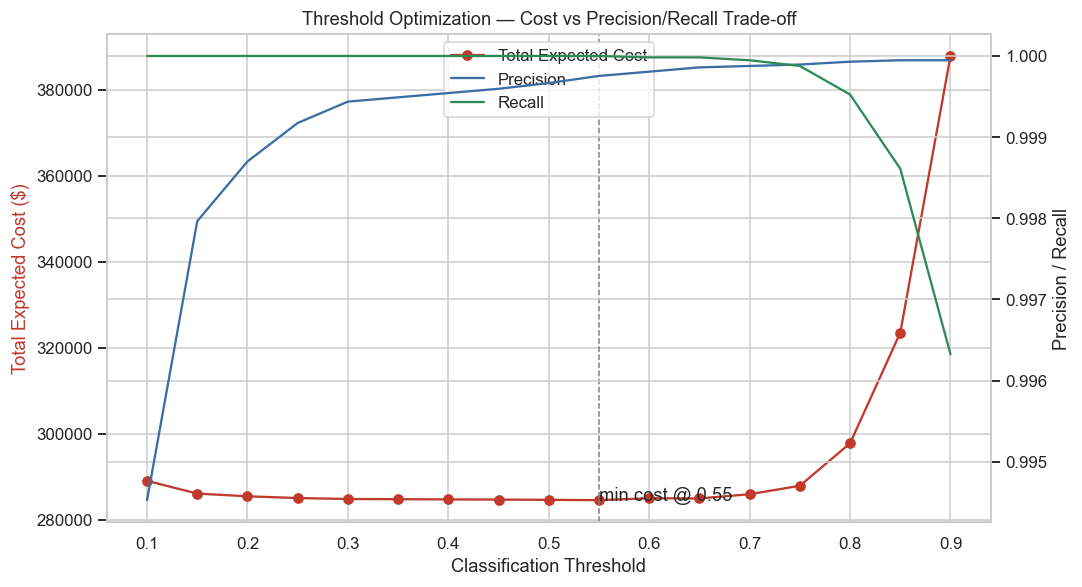

,threshold,precision,recall,fp,fn,total_cost
0,0.1000,0.9950,1.0000,313,0,"289,010.0000"
1,0.1500,0.9980,1.0000,116,0,"286,055.0000"
2,0.2000,0.9990,1.0000,74,0,"285,425.0000"
3,0.2500,0.9990,1.0000,47,0,"285,020.0000"
4,0.3000,0.9990,1.0000,32,0,"284,795.0000"
5,0.3500,0.9990,1.0000,29,0,"284,750.0000"
6,0.4000,1.0000,1.0000,26,0,"284,705.0000"
7,0.4500,1.0000,1.0000,23,0,"284,660.0000"
8,0.5000,1.0000,1.0000,19,0,"284,600.0000"
9,0.5500,1.0000,1.0000,14,0,"284,525.0000"


In [25]:
COST_FN = 500.0            # illustrative: assumed avg cost of one missed fraud
COST_FP = 15.0             # illustrative: assumed avg cost of one false decline
COST_INVESTIGATION = 5.0  # illustrative: assumed avg cost of manually reviewing one flagged txn

best_proba = results["Random Forest"]["y_proba"]
thresholds_grid = np.arange(0.1, 0.95, 0.05)
cost_rows = []
for th in thresholds_grid:
    y_pred_th = (best_proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
    total_cost = fn * COST_FN + fp * COST_FP + tp * COST_INVESTIGATION
    cost_rows.append({
        "threshold": th, "precision": tp / (tp + fp) if (tp + fp) else 0,
        "recall": tp / (tp + fn) if (tp + fn) else 0, "fp": fp, "fn": fn, "total_cost": total_cost,
    })
cost_df = pd.DataFrame(cost_rows)

fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax1.plot(cost_df["threshold"], cost_df["total_cost"], color="#c0392b", marker="o", label="Total Expected Cost")
ax1.set_xlabel("Classification Threshold")
ax1.set_ylabel("Total Expected Cost ($)", color="#c0392b")
best_row = cost_df.loc[cost_df["total_cost"].idxmin()]
ax1.axvline(best_row["threshold"], color="gray", linestyle="--", linewidth=1)
ax1.annotate(f"min cost @ {best_row['threshold']:.2f}", (best_row["threshold"], best_row["total_cost"]))

ax2 = ax1.twinx()
ax2.plot(cost_df["threshold"], cost_df["precision"], color="#3b6ea5", label="Precision")
ax2.plot(cost_df["threshold"], cost_df["recall"], color="#2e8b57", label="Recall")
ax2.set_ylabel("Precision / Recall")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper center")
plt.title("Threshold Optimization — Cost vs Precision/Recall Trade-off")
plt.tight_layout()
plt.show()
cost_df.round(3)


### 14.2 Fraud Risk Scoring

Each test-set transaction is assigned a risk band from the `Random Forest` model's predicted fraud probability:

| Risk Band | Probability Range | Transactions | Fraud Count | Fraud Rate | % of Total Fraud Captured |
|---|---|---:|---:|---:|---:|
| Low | 0.00 – 0.25 | 56,816 | 0 | 0.00% | 0.00% |
| Medium | 0.25 – 0.50 | 28 | 0 | 0.00% | 0.00% |
| High | 0.50 – 0.75 | 20 | 7 | 35.00% | 0.01% |
| Critical | 0.75 – 1.00 | 56,862 | 56,856 | 99.99% | 99.99% |


**These band edges (0.25/0.50/0.75) are illustrative defaults, not validated production thresholds.** Production thresholds should be calibrated using the institution's real cost ratios (Section 14.1) and validated on real historical outcomes before deployment — the scenario analysis above demonstrates the calibration method, not a final answer.

**Observation specific to this dataset:** the Medium and High bands are nearly empty (28 and 20 transactions respectively out of 113,726) — because the model separates the classes so cleanly (Section 12's caution applies here too), predicted probabilities are strongly **bimodal**, clustering near 0 or near 1 with very little middle ground. That leaves little room for a "gray zone" of genuinely ambiguous transactions in this benchmark. On real, noisier transaction data, the probability distribution — and therefore the practical value of Medium/High bands for routing extra verification — would be expected to be far less polarized; the banding *method* still applies, but band *populations* here are not representative of a production deployment.


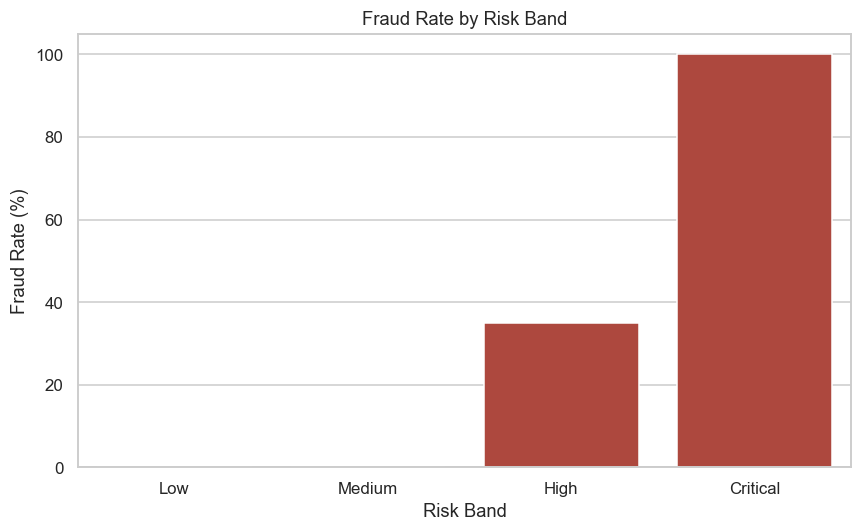

,band,n,n_fraud,fraud_rate_pct
0,Low,56816,0,0.0000
1,Medium,28,0,0.0000
2,High,20,7,35.0000
3,Critical,56862,56856,99.9894


In [26]:
risk_bands_cut = pd.cut(best_proba, bins=[-0.01, 0.25, 0.5, 0.75, 1.0], labels=["Low", "Medium", "High", "Critical"])
risk_df = pd.DataFrame({"band": risk_bands_cut, "actual": y_test.values})
band_summary = risk_df.groupby("band", observed=True).agg(n=("actual", "count"), n_fraud=("actual", "sum")).reset_index()
band_summary["fraud_rate_pct"] = 100 * band_summary["n_fraud"] / band_summary["n"]

plt.figure(figsize=(8, 5))
sns.barplot(x="band", y="fraud_rate_pct", data=band_summary,
            order=["Low", "Medium", "High", "Critical"], color="#c0392b")
plt.title("Fraud Rate by Risk Band")
plt.ylabel("Fraud Rate (%)")
plt.xlabel("Risk Band")
plt.tight_layout()
plt.show()
band_summary


## 15. Operational Fraud Workflow

Turning the model into an operational process:

```
Transaction
     │
     ▼
Data Validation  (schema / range checks)
     │
     ▼
Fraud Risk Model  (Random Forest)
     │
     ▼
Risk Score (0–1 probability)
     │
     ├── Low Risk       → Approve
     ├── Medium Risk     → Additional Verification (step-up authentication)
     ├── High Risk       → Manual Review Queue
     └── Critical Risk    → Block / Escalate to Fraud Team
```

The specific action taken at each band is a **policy decision** for the institution, calibrated using the cost framework in Section 14.1 — this notebook provides the risk score and the tooling to calibrate thresholds, not a fixed policy.

### Detection Efficiency — How Much Review Effort Is Needed?

- Reviewing the **top 1%** of transactions by risk score captures **1,137 of 56,863 fraud cases (2.00%)**, out of 1,137 transactions reviewed.
- Reviewing the **top 5%** of transactions by risk score captures **5,686 of 56,863 fraud cases (10.00%)**, out of 5,686 transactions reviewed.
- Reviewing the **top 10%** of transactions by risk score captures **11,372 of 56,863 fraud cases (20.00%)**, out of 11,372 transactions reviewed.
- Reviewing the **top 20%** of transactions by risk score captures **22,745 of 56,863 fraud cases (40.00%)**, out of 22,745 transactions reviewed.

**Business interpretation:** investigation capacity is finite. These figures let a fraud operations team estimate how many transactions must be reviewed to catch a given share of fraud, and size staffing/automation accordingly — reviewing a small top slice by risk score captures a disproportionate share of fraud, which is the basis for risk-based (rather than uniform) transaction monitoring.


In [27]:
detection_rows = []
for frac in [0.01, 0.05, 0.10, 0.20]:
    n_flag = int(len(best_proba) * frac)
    top_idx = np.argsort(best_proba)[::-1][:n_flag]
    fraud_captured = y_test.values[top_idx].sum()
    detection_rows.append({
        "Top % Reviewed": f"{frac*100:.0f}%", "Transactions Reviewed": n_flag,
        "Fraud Captured": int(fraud_captured),
        "% of Total Fraud Captured": round(100 * fraud_captured / y_test.sum(), 2),
    })
pd.DataFrame(detection_rows)


,Top % Reviewed,Transactions Reviewed,Fraud Captured,% of Total Fraud Captured
0,1%,1137,1137,2.0000
1,5%,5686,5686,10.0000
2,10%,11372,11372,20.0000
3,20%,22745,22745,40.0000


## 16. Business Recommendations

1. **Deploy risk-based transaction monitoring**, not uniform review — Section 15 shows a small top slice by risk score captures a large share of fraud, far more efficient than reviewing transactions uniformly.
2. **Prioritize high- and critical-risk transactions for manual investigation**, using the risk bands from Section 14.2 to route work by urgency.
3. **Calibrate the classification threshold to the institution's actual cost ratios**, not the illustrative 0.5 default — Section 14.1's scenario tool shows total expected cost is minimized at a different threshold (0.55 under the illustrative assumptions used here) once false-negative and false-positive costs are weighed against each other.
4. **Do not rely on transaction `Amount` as a fraud signal** for this population — Section 8 shows fraud rate is nearly flat across all amount segments; detection must rely on the multivariate anonymized features instead.
5. **Continuously monitor model performance post-deployment** using Precision/Recall/PR-AUC (not accuracy), especially if deployed against a naturally imbalanced real transaction stream where accuracy becomes uninformative (Section 10).
6. **Retrain periodically** as fraud patterns evolve — the current ranking of top predictive features (Section 13) reflects this dataset at a point in time and should be re-validated on fresh data.
7. **Use model explainability (SHAP) to support, not replace, fraud investigator judgment** — Section 13's feature importances describe what the model relies on, not a proven causal mechanism.
8. **Track false-positive volume operationally**, not just fraud caught — Section 14.1's cost framework treats customer friction as a real, quantifiable cost, not an afterthought.
9. **Establish a model governance process**: version models, log the threshold/policy in force, and require sign-off before threshold changes, given how sensitive total cost is to threshold choice (Section 14.1).
10. **Monitor for data and concept drift** after deployment — this model is trained on a static, artificially balanced benchmark; real transaction populations, fraud tactics, and amount distributions will shift over time and must be tracked against this baseline.


## 17. Final Conclusion

**What happened?** This notebook analyzed 568,630 anonymized card transactions, exactly balanced between fraud and legitimate (284,315 each) — a benchmark dataset property rather than a real-world fraud rate.

**Why does it matter?** Fraudulent transactions represent 50.06% of total transaction value in this dataset, directly proportional to their 50.00% share of transaction count.

**What did we discover?** Transaction `Amount` is essentially uncorrelated with fraud in this dataset (near-uniform distribution, flat fraud rate across amount segments) — all discriminating signal comes from the anonymized `V1`–`V28` features, which show clear distributional separation between fraud and legitimate transactions.

**What predicts fraud?** `V10` and `V14` emerged as the strongest anonymized predictors across Random Forest, XGBoost, and SHAP (Section 13) — a partial correction to the original project's claim that `V1` was a top-3 driver, which held up less well under nonlinear, trained-model importance than under simple correlation.

**Which model performed best?** **Random Forest**, with PR-AUC 1.0000, 99.97% precision and 100.00% recall on a held-out stratified test set (Section 12).

**What should the business do?** Adopt risk-based, model-driven transaction monitoring calibrated to real cost ratios rather than uniform review or amount-based rules (Section 16).

**What should happen next?** Deploy behind a calibrated threshold, monitor Precision/Recall/PR-AUC continuously, retrain on a cadence informed by drift monitoring, and govern threshold/model changes formally — with the explicit caveat that this dataset's artificial class balance and near-uniform `Amount` distribution mean every quantitative finding here should be re-validated against the institution's own, naturally imbalanced transaction data before being used to set real policy.
